In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42

df = pd.read_csv("../data/clean/selected_features.csv")

display(df.head())
print(f"\nThe shape is: {df.shape}")
print(f"\nThe columns are: {df.columns}")

,application_mode_group,course_name,prev_qual_level,debtor,tuition_fees_up_to_date,gender,scholarship_holder,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,age_at_enrollment,admission_grade,target
0,2nd phase - general contingent,Animation and Multimedia Design,2,0,1,1,0,0,0,0.000000,20,127.3,Dropout
1,International student (bachelor),Tourism,2,0,0,1,0,6,6,13.666667,19,142.5,Graduate
2,1st phase - general contingent,Communication Design,2,0,0,1,0,6,0,0.000000,19,124.8,Dropout
3,2nd phase - general contingent,Journalism and Communication,2,0,1,0,0,6,5,12.400000,20,119.6,Graduate
4,Over 23 years old,Social Service (evening attendance),2,0,1,0,0,6,6,13.000000,45,141.5,Graduate



The shape is: (3630, 13)

The columns are: Index(['application_mode_group', 'course_name', 'prev_qual_level', 'debtor',
       'tuition_fees_up_to_date', 'gender', 'scholarship_holder',
       'curricular_units_2nd_sem_enrolled',
       'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade',
       'age_at_enrollment', 'admission_grade', 'target'],
      dtype='str')


In [2]:
df["target"].unique()

<StringArray>
['Dropout', 'Graduate']
Length: 2, dtype: str

In [3]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

## Selected Features

The model uses the team's final 12 selected features
from selected_features.csv.

In [4]:
selected_nominal_features = [
    "application_mode_group",
    "course_name"
]

selected_ordinal_features = [
    "prev_qual_level"
]

selected_binary_features = [
    "debtor",
    "tuition_fees_up_to_date",
    "gender",
    "scholarship_holder"
]

selected_numerical_features = [
    "curricular_units_2nd_sem_enrolled",
    "curricular_units_2nd_sem_approved",
    "curricular_units_2nd_sem_grade",
    "age_at_enrollment",
    "admission_grade"
]

In [5]:
ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaling", MinMaxScaler()),
])
nominal_pipeline = Pipeline([("encoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
numerical_pipeline = Pipeline([("scaling", MinMaxScaler())])

In [6]:
# Preprocessor for column transformation
preprocessor = ColumnTransformer([
    ("ordinal", ordinal_pipeline, selected_ordinal_features),
    ("nominal", nominal_pipeline, selected_nominal_features),
    ("numerical", numerical_pipeline, selected_numerical_features),
    ("binary", "passthrough", selected_binary_features),
])

In [7]:
logistic_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

## Logistic Regression - Model Training

In [8]:
logistic_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['application_mode_group','course_name','prev_qual_level',..., 'curricular_units_2nd_sem_grade','age_at_enrollment','admission_grade']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

## Model Evaluation - Training Data

In [9]:
y_train_pred = logistic_pipeline.predict(X_train)

# calculate training metrics
print("Training accuracy:",
      round(accuracy_score(y_train, y_train_pred), 3))

print("Precision (Dropout):",
      round(precision_score(y_train, y_train_pred, pos_label="Dropout"), 3))

print("Recall (Dropout):",
      round(recall_score(y_train, y_train_pred, pos_label="Dropout"), 3))

print("F1 (Dropout):",
      round(f1_score(y_train, y_train_pred, pos_label="Dropout"), 3))

Training accuracy: 0.909
Precision (Dropout): 0.944
Recall (Dropout): 0.815
F1 (Dropout): 0.875


In [10]:
print(classification_report(y_train, y_train_pred))

              precision    recall  f1-score   support

     Dropout       0.94      0.82      0.87      1137
    Graduate       0.89      0.97      0.93      1767

    accuracy                           0.91      2904
   macro avg       0.92      0.89      0.90      2904
weighted avg       0.91      0.91      0.91      2904



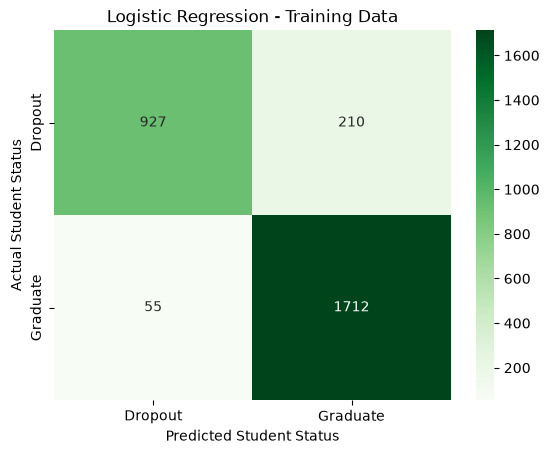

In [11]:
# confusion matrix

cm = confusion_matrix(
    y_train,
    y_train_pred,
    labels=["Dropout", "Graduate"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Dropout", "Graduate"],
    yticklabels=["Dropout", "Graduate"]
)

plt.title("Logistic Regression - Training Data")
plt.xlabel("Predicted Student Status")
plt.ylabel("Actual Student Status")
plt.show()

### Initial Training Results - Observations

- Training accuracy: 90.9%.
- Dropout precision: 94.4%.
- Dropout recall: 81.5%.
- Dropout F1-score: 87.5%.
- The model uses the team's 12 selected features.
- Hyperparameter tuning will focus on improving
  dropout recall.

## Logistic Regression - Cross-Validation

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

#cross-validation strategy

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=RANDOM_STATE
)

In [13]:
#evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="Dropout"
    ),
    "recall": make_scorer(
        recall_score, pos_label="Dropout"
    ),
    "f1": make_scorer(
        f1_score, pos_label="Dropout"
    )
}

In [14]:
cv_results = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True
)

cv_summary = pd.DataFrame({
    "Training": [
        cv_results["train_accuracy"].mean(),
        cv_results["train_precision"].mean(),
        cv_results["train_recall"].mean(),
        cv_results["train_f1"].mean()
    ],
    "Validation": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean()
    ]
}, index=["Accuracy", "Precision", "Recall", "F1"])

cv_summary.round(3)

,Training,Validation
Accuracy,0.907,0.902
Precision,0.945,0.934
Recall,0.811,0.807
F1,0.873,0.865


### Cross-Validation - Observations

- Validation accuracy: 90.2%.
- Validation precision: 93.4%.
- Validation recall: 80.7%.
- Validation F1-score: 86.5%.
- Training and validation results are similar,
  suggesting limited overfitting.
- Feature selection was performed before cross-validation.
- Hyperparameter tuning will focus on improving recall
  while maintaining reasonable precision.

## Logistic Regression - Hyperparameter Tuning

In [15]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

In [16]:
grid_search = GridSearchCV(
    logistic_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit="recall",
    return_train_score=True
)

grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': make_scorer(f...label=Dropout), 'precision': make_scorer(p...label=Dropout), 'recall': make_scorer(r...label=Dropout)}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is 

In [17]:
print("Best parameters:", grid_search.best_params_)

print("Best validation recall:",
      round(grid_search.best_score_, 3))

Best parameters: {'model__C': 10, 'model__class_weight': 'balanced'}
Best validation recall: 0.862


In [18]:
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results[[
    "param_model__C",
    "param_model__class_weight",
    "mean_test_accuracy",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1"
]].sort_values(
    "mean_test_recall",
    ascending=False
).round(3)

,param_model__C,param_model__class_weight,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
7,10.00,balanced,0.906,0.895,0.862,0.878
5,1.00,balanced,0.899,0.892,0.845,0.868
6,10.00,NaN,0.909,0.933,0.828,0.877
3,0.10,balanced,0.883,0.867,0.828,0.847
1,0.01,balanced,0.847,0.802,0.808,0.805
4,1.00,NaN,0.902,0.934,0.807,0.865
2,0.10,NaN,0.884,0.930,0.762,0.837
0,0.01,NaN,0.832,0.922,0.624,0.744


### Hyperparameter Tuning - Observations

- Eight parameter combinations were tested using
  four-fold cross-validation.
- The best parameters are C=10 and
  class_weight="balanced".
- Dropout recall increased from 80.7% to 86.2%.
- Precision decreased from 93.4% to 89.5%,
  while accuracy and F1-score improved.
- The tuned model identifies more dropout students,
  supporting our main business objective.
- The test dataset was not used directly during
  hyperparameter tuning.

## Tuned Logistic Regression - Best Model

In [19]:
best_logistic_pipeline = grid_search.best_estimator_

best_logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['Dropout','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['application_mode_group','course_name','prev_qual_level',..., 'curricular_units_2nd_sem_grade','age_at_enrollment','admission_grade']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specified

## Tuned Logistic Regression - Test Evaluation

In [20]:
y_test_pred = best_logistic_pipeline.predict(X_test)

print("Test accuracy:",
      round(accuracy_score(y_test, y_test_pred), 3))

print("Precision (Dropout):",
      round(precision_score(y_test, y_test_pred, pos_label="Dropout"), 3))

print("Recall (Dropout):",
      round(recall_score(y_test, y_test_pred, pos_label="Dropout"), 3))

print("F1 (Dropout):",
      round(f1_score(y_test, y_test_pred, pos_label="Dropout"), 3))

Test accuracy: 0.909
Precision (Dropout): 0.901
Recall (Dropout): 0.863
F1 (Dropout): 0.881


In [21]:
#classification report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

     Dropout       0.90      0.86      0.88       284
    Graduate       0.91      0.94      0.93       442

    accuracy                           0.91       726
   macro avg       0.91      0.90      0.90       726
weighted avg       0.91      0.91      0.91       726



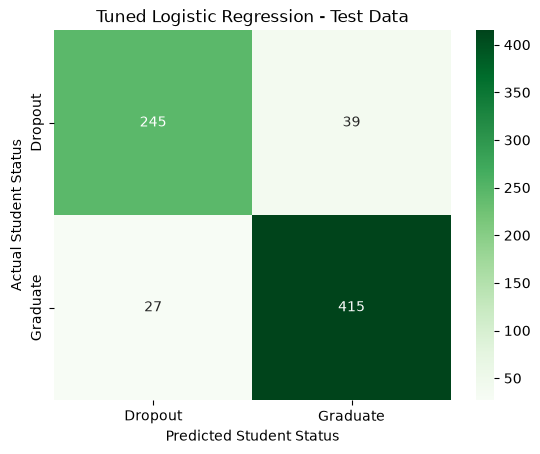

In [22]:
#confusion matrix

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["Dropout", "Graduate"]
)

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Dropout", "Graduate"],
    yticklabels=["Dropout", "Graduate"]
)

plt.title("Tuned Logistic Regression - Test Data")
plt.xlabel("Predicted Student Status")
plt.ylabel("Actual Student Status")
plt.show()

### Test Evaluation - Observations

- Test accuracy: 90.9%.
- Dropout precision: 90.1%.
- Dropout recall: 86.3%.
- Dropout F1-score: 88.1%.
- The model correctly identified 245 out of 284
  dropout students.
- 39 dropout students were missed.
- 27 graduates were incorrectly classified as dropouts.
- Test and validation results are very similar.
- Reducing the model from 15 to 12 features
  maintained the same test dropout recall.

## Tuned Logistic Regression - Feature Importance

In [23]:
feature_names = best_logistic_pipeline.named_steps[
    "preprocess"
].get_feature_names_out()

coefficients = best_logistic_pipeline.named_steps[
    "model"
].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": -coefficients
})

feature_importance["Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

feature_importance.head(10)

,Feature,Coefficient,Importance
28,numerical__curricular_units_2nd_sem_approved,-18.529998,18.529998
27,numerical__curricular_units_2nd_sem_enrolled,17.557065,17.557065
29,numerical__curricular_units_2nd_sem_grade,-3.636593,3.636593
5,nominal__application_mode_group_International ...,-3.138919,3.138919
33,binary__tuition_fees_up_to_date,-2.684839,2.684839
17,nominal__course_name_Informatics Engineering,1.657673,1.657673
13,nominal__course_name_Basic Education,1.553323,1.553323
30,numerical__age_at_enrollment,1.179727,1.179727
0,ordinal__prev_qual_level,1.177996,1.177996
32,binary__debtor,1.176977,1.176977


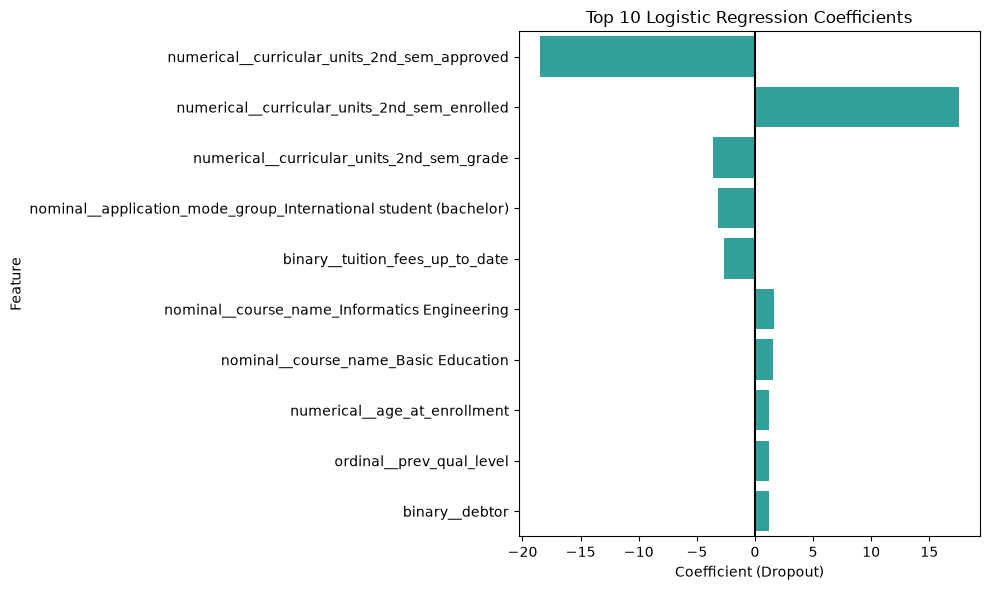

In [24]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Coefficient",
    y="Feature",
    color="lightseagreen"
)

plt.axvline(0, color="black")
plt.title("Top 10 Logistic Regression Coefficients")
plt.xlabel("Coefficient (Dropout)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Feature Importance - Observations

- Approved and enrolled curricular units have the
  largest absolute coefficients.
- Higher numbers of approved units are associated
  with lower dropout risk.
- Higher numbers of enrolled units, holding approved
  units constant, are associated with higher risk.
- Higher second-semester grades and having tuition
  fees up to date are associated with lower risk.
- Academic performance appears to be particularly
  important in predicting student dropout.
- Coefficients represent associations, not causation.
- Correlation between features and differences in
  scaling and encoding can affect their interpretation.

## Dropout Risk Prediction - Enrolled Students

In [25]:
df_enrolled = pd.read_csv(
    "../data/clean/enrolled_selected_features.csv"
)

X_enrolled = df_enrolled.copy()

df_enrolled["predicted_status"] = (
    best_logistic_pipeline.predict(X_enrolled)
)

df_enrolled["dropout_probability"] = (
    best_logistic_pipeline.predict_proba(X_enrolled)[:, 0]
)

In [26]:
# checking order
best_logistic_pipeline.classes_

array(['Dropout', 'Graduate'], dtype=object)

In [27]:
df_enrolled["predicted_status"].value_counts()

predicted_status
Graduate    411
Dropout     383
Name: count, dtype: int64

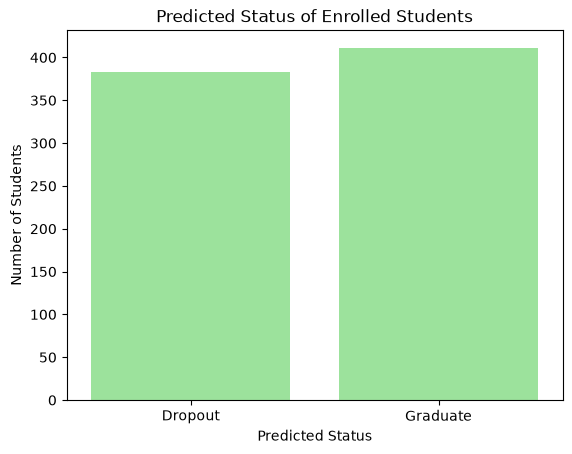

In [28]:
#visualise predicted outcomes

sns.countplot(
    data=df_enrolled,
    x="predicted_status",
    color="lightgreen"
)

plt.title("Predicted Status of Enrolled Students")
plt.xlabel("Predicted Status")
plt.ylabel("Number of Students")
plt.show()

In [29]:
#students with the highest predicted dropout risk

enrolled_predictions = df_enrolled[[
    "predicted_status",
    "dropout_probability"
]].sort_values(
    "dropout_probability",
    ascending=False
)

enrolled_predictions.head(10)

,predicted_status,dropout_probability
553,Dropout,0.999990
156,Dropout,0.999985
390,Dropout,0.999959
29,Dropout,0.999931
19,Dropout,0.999828
484,Dropout,0.999663
162,Dropout,0.999341
424,Dropout,0.999331
537,Dropout,0.999285
394,Dropout,0.999207


### Enrolled Students - Observations

- The model was applied to 794 currently enrolled
  students.
- 383 students (48.2%) were classified as at risk
  of dropping out.
- 411 students (51.8%) were classified as likely
  to graduate.
- Students can be ranked according to their
  estimated dropout risk.
- This could help the university prioritise
  academic and financial support.
- These predictions are estimates, not confirmed
  future outcomes.
- The risk scores should not be interpreted as
  calibrated probabilities.

## Save Final Logistic Regression Model

In [30]:
import joblib

joblib.dump(
    best_logistic_pipeline,
    "../models/logistic_regression.joblib"
)

['../models/logistic_regression.joblib']

## Final Conclusions

Logistic Regression was developed using the team's
12 selected features and shared preprocessing pipeline.

Hyperparameter tuning improved validation dropout
recall from 80.7% to 86.2%.

The final model achieved 90.9% accuracy and 86.3%
dropout recall on the test dataset.

Reducing the number of features from 15 to 12
maintained the same test dropout recall.

Second-semester academic performance, particularly
approved and enrolled curricular units, appears
to play an important role in dropout prediction.

The model was also applied to currently enrolled
students, identifying 383 students who may benefit
from additional support.

### Business Recommendations

- Monitor students with low academic performance.
- Provide additional academic support to students
  struggling to complete their curricular units.
- Offer financial support or guidance to students
  experiencing difficulties with tuition payments.
- Use model predictions to prioritise support,
  rather than to make automatic decisions.

### Limitations

- Predictions do not establish causation.
- Feature selection was performed before
  cross-validation.
- The test dataset was previously examined
  during team model development.
- The model uses second-semester academic results,
  limiting its use for early intervention.
- The actual final outcomes of enrolled students
  are unknown.
- Predicted risk scores are not calibrated probabilities.
- Further validation on new students is recommended.